![Banner](../images/09_13_banner_rs_capstones.png)


# Thirty-five Years of Change around Pucallpa, Peru

Pucallpa, in the Peruvian Amazon, has expanded along roads and rivers since the 1980s.


## Overview

We
download eight real Landsat composites (1985-2020) with `get_images`-style cached fetches into a
`RasterCube` and track forest with a normalised difference of NIR and SWIR1 (NDMI): dense forest
is bright in NIR and dark in SWIR.

These composites are **8-bit display products**, so index values are relative, not physical.
Their NDMI distributions are nonetheless similar across years, so we use one threshold
(NDMI > 0.30 = forest) after checking it against the imagery, and exclude pixels that were water
(dark NIR) in any year so that river meandering is not counted as deforestation.


## Setup

Libraries and `fetch`, which returns a local GeoTIFF for each Pucallpa composite, downloading it only when `data/` does not already have the file.

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Imports and the cached Landsat composites. fetch() downloads a year only if it is not already on disk.

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

import os
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import geolattice.rsense as rs
from geolattice.rsense.optical.sensors import landsat  # registers Landsat band names used by RasterCube

plt.rcParams.update({"figure.dpi": 110})
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"))

# Same folder as the Landsat tutorial, so composites already downloaded there are reused.
DATA = next((p for p in (Path("../../../../Data/08_remote_sensing/08_02_optical"), Path("Data/08_remote_sensing/08_02_optical"))
             if p.is_dir()), Path("../../../../Data/08_remote_sensing/08_02_optical"))  # shared optical data, from this folder or the repository root
DATA.mkdir(parents=True, exist_ok=True)

RAW = "https://raw.githubusercontent.com"
URLS = {
    **{f"pucallpa_{y}.tif": f"{RAW}/opengeos/data/main/landsat/{y}.tif" for y in range(1985, 2021, 5)},
}

def fetch(name):
    """Return a local path, downloading the composite if the cache is empty."""
    path = DATA / name
    if path.exists() and os.path.getsize(path) > 0:
        print(f"Found {name} locally; using cached version.")
    else:
        print(f"Downloading {name} ...")
        urllib.request.urlretrieve(URLS[name], path)
    return path


geolattice.rsense 0.2.0.dev0 | backend: cpu


### Data

The dataset consists of multi-temporal Landsat satellite composite images of the Pucallpa region in Peru, spanning every 5 years from 1985 to 2020. Each composite brings together specific spectral bands (SWIR1, NIR, red, green) essential for analyzing vegetation change, land clearing, and water. The images are stored as GeoTIFF files and are combined into a time-series data structure (RasterCube) for visualization and change detection analysis.  All data are avilable 
[here](https://www.dropbox.com/scl/fo/c7b6estcd609sp9gdwhuu/AMyl1zO3KuhaiHzB6PiwQkM?rlkey=s458rnzp553y57e02mjx01ri6&dl=0) for download. 


In [2]:
# Step 1: Define the target years for the timeseries (every 5 years from 1985 to 2020)
years = list(range(1985, 2021, 5))

# Step 2: Get the file paths for each year's Landsat composite image in the Pucallpa region.
# The 'fetch' function retrieves the file path for each particular year in the specified format.
paths = [fetch(f"pucallpa_{y}.tif") for y in years]

# Step 3: Load all images as a time-series RasterCube, associating each file with its date 
# (using July 1st for every year) and specifying relevant spectral bands (SWIR1, NIR, red, green).
# The 'sensor' parameter ensures correct band mapping for Landsat.
cube = rs.RasterCube.from_files(
    paths,
    [f"{y}-07-01" for y in years],                     # Use July 1st as the date for each composite
    ["swir16", "nir", "red", "green"],                 # Bands used for further analysis/visualization
    sensor="landsat"
)

# Step 4: Filter out pixels where NIR band is zero (clouds/shadows or water),
# then normalize band values to [0,1] scale (from the original 8-bit 0-255 range).
cube.ds = cube.ds.where(cube.ds["nir"] > 0).astype("float32") / 255.0

# Step 5: Show the resulting RasterCube (for interactive notebooks, this displays summary info).
cube

Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as 

<RasterCube 8 dates × 377×697 px, bands=['swir16', 'nir', 'red', 'green'], 1985-07-01 → 2020-07-01, crs=EPSG:4326>

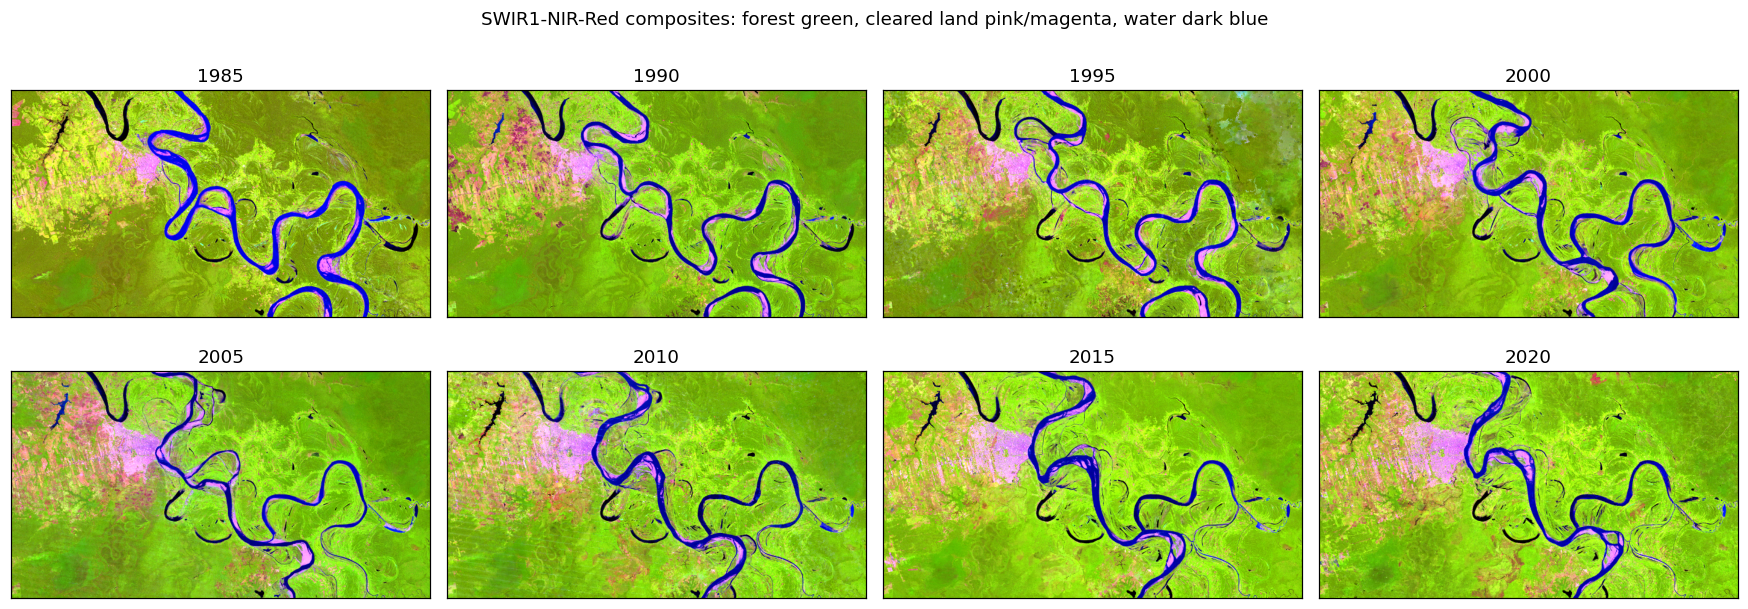

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for k, (ax, y) in enumerate(zip(axes.ravel(), years)):
    rs.viz.plot_rgb(cube.ds.isel(time=k), ["swir16", "nir", "red"], ax=ax, title=str(y))
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("SWIR1-NIR-Red composites: forest green, cleared land pink/magenta, water dark blue")
plt.tight_layout(); plt.show()

The same eight composites, animated, make the expansion easier to follow than flipping between
panels: watch the magenta clearing grow out from the city and along the roads.


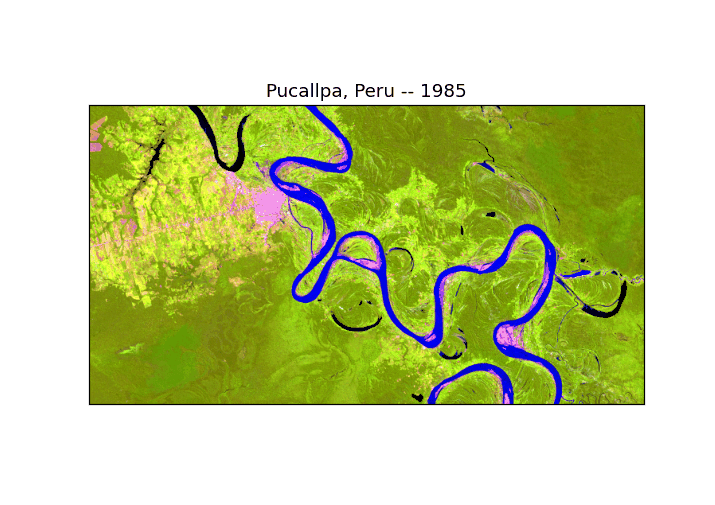

In [4]:
# This block creates an animated GIF showing 35 years of change in the Pucallpa region from Landsat composites

import matplotlib.animation as animation           # For creating animations in matplotlib
from IPython.display import Image as IPImage       # For displaying images in Jupyter notebooks
from geolattice.rsense.viz.stretch import rgb as make_rgb  # For turning multispectral bands into displayable RGB images

# Set the output directory for the animation, creating it if it doesn't exist
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

# Prepare a list of RGB images (one per year) for animation, replacing any NaNs with zeroes for display
frames = [
    np.nan_to_num(
        make_rgb(
            cube.ds.isel(time=k),                 # Get the scene at year index k
            ["swir16", "nir", "red"]              # Use SWIR1, NIR, and red bands as RGB channels
        ).values
    )
    for k in range(len(years))
]

# Set up the matplotlib figure and axis
fig, ax = plt.subplots(figsize=(6.5, 4.6))

# Display the first frame as the initial image
im = ax.imshow(frames[0], origin="upper")
ax.set_xticks([])
ax.set_yticks([])
ttl = ax.set_title("")

# The animation update function: set a new frame and update the title with the year
def _update(k):
    im.set_data(frames[k])
    ttl.set_text(f"Pucallpa, Peru -- {years[k]}")
    return im, ttl

# Create the animation, advancing with a 0.6 second interval between frames
anim = animation.FuncAnimation(fig, _update, frames=len(years), interval=600)

# Save the animation as a GIF to the output directory
gif_path = OUT_DIR / "pucallpa_1985_2020.gif"
anim.save(gif_path, writer=animation.PillowWriter(fps=1.5))

# Close the figure to free memory
plt.close(fig)

# Display the resulting GIF inside the notebook
IPImage(filename=str(gif_path))

### Normalize Difference Moisture Index (NDMI)


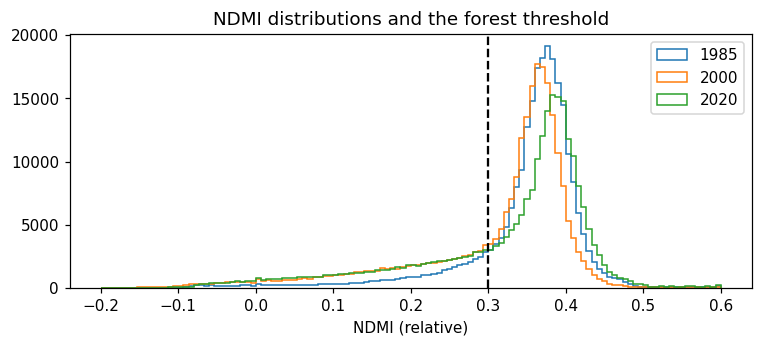

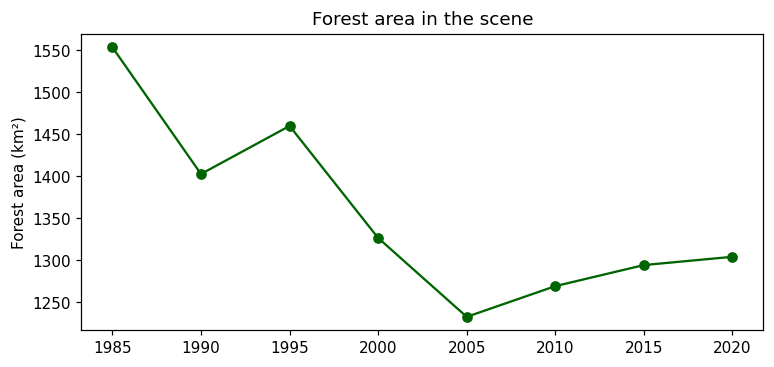

Forest loss 1985 -> 2020: 249 km² (-16 %)


In [5]:
# Calculate NDMI (Normalized Difference Moisture Index) for each pixel and time step
ndmi = cube.ds.rs.index("NDMI")

# Identify all pixels that are ever water based on NIR reflectance (< 0.25) at any time
water_ever = (cube.ds["nir"] < 0.25).any("time")

# Define "forest" pixels:
# Pixels where NDMI > 0.3 (i.e., moist vegetation) and which are not ever classified as water
forest = (ndmi > 0.30).where(ndmi.notnull() & ~water_ever)

# Plot NDMI value distributions for selected years to show the separation between forest and non-forest
fig, ax = plt.subplots(figsize=(8, 3))
for k in [0, 3, 7]:
    # Plot a histogram of NDMI values for year k
    ax.hist(ndmi.isel(time=k).values.ravel(), bins=120, range=(-0.2, 0.6), histtype="step", label=str(years[k]))
# Draw a vertical line to illustrate the chosen forest threshold (NDMI=0.3)
ax.axvline(0.30, color="k", ls="--")
ax.legend()
ax.set(xlabel="NDMI (relative)", title="NDMI distributions and the forest threshold")
plt.show()

# Compute the area of each pixel in square kilometers using the grid size and latitude
# For a geographic grid at ~8.4° S: 
# Longitude degrees to km ≈ 111.32
# Latitude degrees to km ≈ 110.57 * cos(latitude)
res_deg = abs(float(cube.ds.x[1] - cube.ds.x[0]))
px_km2 = (res_deg * 111.32) * (res_deg * 110.57 * np.cos(np.radians(8.4)))

# Sum the number of forest pixels at each time then multiply by the per-pixel area to get area in km²
area = (forest.sum(("y", "x")) * px_km2).to_series()
area.index = years

# Plot forest area per year as a time series
ax = area.plot(marker="o", figsize=(8, 3.5), color="darkgreen")
ax.set(ylabel="Forest area (km²)", xlabel="", title="Forest area in the scene")
plt.show()

# Print a summary of forest loss from the first to last year in the time series
print(f"Forest loss 1985 -> 2020: {area.iloc[0] - area.iloc[-1]:.0f} km² "
      f"({(area.iloc[-1] / area.iloc[0] - 1) * 100:.0f} %)")
# --- End explanation ---

### Persistent Forest Loss


          1990  1995  2000  2005  2010  2015  2020
km² lost  69.4  23.5  45.4  23.9  28.5  46.4  97.4


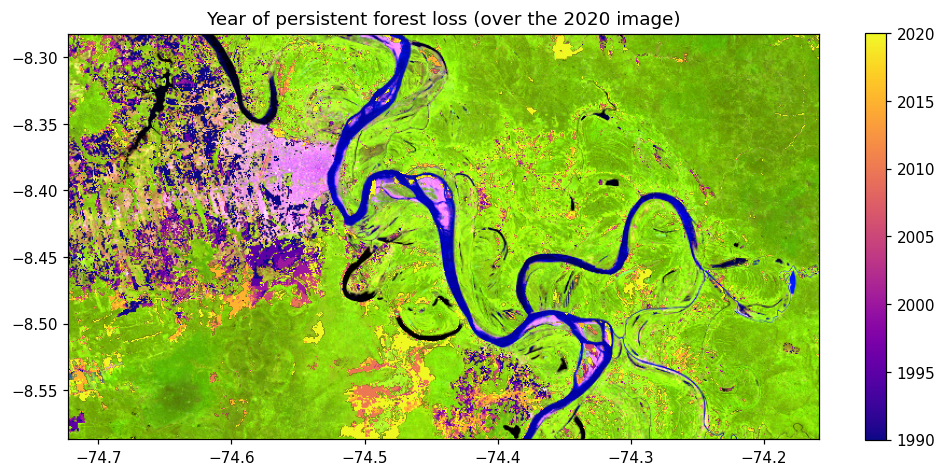

In [6]:
# The aim here is to identify 'persistent forest loss': pixels that are classified as forest in the first year (1985),
# but transition to non-forest at any time k, after which they never recover to forest in later years.
# This strict definition rules out temporary changes (e.g., from floods or haze).

# Convert the 'forest' mask (True for forest pixels, False for others) to a boolean numpy array,
# filling NaNs with 1 (i.e., treat unknown as forest), to aid reliable logical operations.
f = forest.fillna(1).astype(bool).values

# Initialize an array, 'lost', to store the year of persistent loss for each pixel.
# Initially, all set to zero (means 'no persistent loss detected').
lost = np.zeros(f.shape[1:], dtype="int16")

# Iterate backwards over all years except the first (from last to second year).
# For each year k, find pixels that:
#   - were forest in 1985 (f[0])
#   - AND are non-forest in all years from k onwards (i.e., did not revert to forest after being lost)
for k in range(len(years) - 1, 0, -1):
    persistent = f[0] & ~f[k:].any(axis=0)  # only ever lost once, no regrowth after year k
    lost[persistent] = years[k]

# Create a data array with the year of persistent forest loss per pixel (NaN if not lost)
loss_da = ndmi.isel(time=0).copy(data=np.where(lost > 0, lost, np.nan)).rename("year of persistent loss")

# Print a summary: for each loss year, show how many square kilometers were lost that year.
# (value_counts by year, rescaled by pixel area, rounded to 0.1 km², shown as a data frame)
print(
    pd.Series(lost[lost > 0])
      .value_counts().sort_index()
      .mul(px_km2).round(1)
      .rename("km² lost").to_frame().T
)

# Visualization:
# - RGB context: show the most recent satellite image (2020 composite) as the basemap.
# - Overlay: year of persistent forest loss per pixel, mapped through a 'plasma' colormap.
fig, ax = plt.subplots(figsize=(11, 6))
rs.viz.plot_rgb(cube.ds.isel(time=-1), ["swir16", "nir", "red"], ax=ax, title="")
rs.viz.plot_raster(loss_da, ax=ax, cmap="plasma", title="Year of persistent forest loss (over the 2020 image)")
plt.show()

Persistent loss spreads outward from the city and along roads. Requiring that a pixel stays
non-forest in every later image removes most noise from haze, flooding and regrowth; the
year-to-year area curve is still noisy for those reasons. Module 9 and Module 19 introduce more
robust change detection and time-series methods.


## Summary and Conclusion

In this notebook, we investigated patterns of persistent forest loss around Pucallpa, Peru using multi-year Landsat satellite imagery. By applying a conservative approach that only marks loss when forest does not recover in subsequent years, we reduced the effects of seasonal noise, temporary clearing, and regrowth. The spatiotemporal analysis revealed that deforestation spread outward from the city and along major roads, forming recognizable patterns of land use expansion.

Our workflow, using spectral indices, logical masking, and multi-temporal raster analysis, demonstrates a practical technique for quantifying land cover change across decades. While robust, this method may still miss subtle changes or overestimate loss in regions where forest regrows or where pixels are affected by mixed signals. Future modules will extend these concepts with more advanced time series and change detection tools, enabling finer discrimination of land dynamics at scale.

The methods shown here can be adapted to other landscapes and serve as a launching point for more detailed remote sensing projects focused on monitoring, conservation, and land management planning.
